# Case Study 03 — Did the Email Campaign Increase Conversions?

**Bernoulli and binomial outcomes · two-proportion z-test · CI for a difference in proportions · absolute vs
relative lift · permutation test · Fisher's exact test · the "openers" selection trap · campaign ROI**

| | |
|---|---|
| **Domain** | Marketing: cross-sell campaign for personal loans |
| **Stakeholder** | Head of Marketing and the Campaign Analytics lead |
| **Difficulty** | Beginner |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 01 (proportion CIs, hypothesis tests), Case 02 (contingency tables, chi-square) |
| **Data** | 80,000 eligible customers with a random 15% holdout; a 360-customer RM-call pilot |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. Why a conversion is a **Bernoulli** trial, a count of conversions is **binomial**, and what that implies for
   uncertainty.
2. How to compare two conversion rates with a **two-proportion z-test** and a **confidence interval for the
   difference**, and why the CI matters more than the p-value.
3. How to report **absolute lift** (percentage points) and **relative lift** (%), and why mixing them up
   misleads.
4. Why "**people who opened the email converted 3× more**" is *not* evidence that the email works.
5. When large-sample tests break down and **Fisher's exact test** is needed.
6. How to turn a lift estimate, with its uncertainty, into a **go/no-go decision**.

## Section 1 — Business context

You are a data scientist in the **Marketing Analytics** team of a retail bank. Last month Marketing emailed a
pre-approved personal-loan offer to existing customers. Following the bank's campaign standard, the CRM system
**randomly held out 15% of eligible customers**, who received no email. Conversion means a personal loan
disbursed within 30 days of the send date.

The Head of Marketing forwards the campaign dashboard and writes:

> *"Great result! Customers who opened the email converted at almost 4%, nearly three times the rate of those who
> didn't open it. I want to roll this out to the whole base every quarter and double the email budget. Can
> Analytics sign off the result? Also, the Affluent team ran a small pilot where relationship managers phoned
> customers about the offer. It looks even better. Should we scale that too?"*

Two claims to check: the email "worked" (based on openers vs non-openers), and the RM call pilot "looks even
better".

## Section 2 — Business questions

1. Did the email campaign increase personal-loan conversions? By how much?
2. Is the "openers converted 3× more" claim a valid measure of the campaign's effect?
3. Is the campaign worth repeating, and is the uncertainty small enough to decide?
4. Did the RM-call pilot work, and should it be scaled?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Did the email increase conversions? | Is p(email) − p(holdout) > 0? How large is it? | **Two-proportion z-test**, **CI for the difference**, relative-lift CI, permutation test |
| 1a | Was the experiment set up correctly? | Does the observed group split match the planned 85/15? | **Sample-ratio-mismatch (SRM)** check (binomial / chi-square goodness of fit) |
| 2 | Is "openers vs non-openers" valid? | Is opening randomly assigned? Do openers differ even without the email? | Design reasoning + comparison against the holdout |
| 3 | Is it worth repeating? | Does the CI for the lift clear the break-even lift? | CI-based decision with campaign economics |
| 4 | Did the RM pilot work? | Is p(call) > p(no call) with tiny counts? | **Fisher's exact test** (small expected counts), CI for the difference |

**Why the holdout is the key design element:** because the holdout was chosen *at random*, the two groups are
statistically alike in every respect (income, engagement, need for a loan) except that one got the email. So
the difference in conversion is an estimate of the **causal effect** of sending the email. This is the one
case so far where a causal claim is justified, and only for the comparison the randomisation protects
(email vs holdout).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, PRIMARY, HIGHLIGHT, INK, INK_MUTED
from statistical_tests import proportion_ci, cohens_h

CASE_DIR = ROOT / "case_studies" / "03_email_campaign_conversion"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(303)
pct = plt.FuncFormatter(lambda v, _: f"{v:.1%}")

PLANNED_HOLDOUT = 0.15
# Campaign economics (from Finance / Marketing)
VALUE_PER_LOAN = 9_000      # ₹ net present value of one incremental personal loan
COST_PER_EMAIL = 0.25       # ₹ send cost per email
FIXED_COST = 200_000        # ₹ creative, offer design and campaign management

## Section 4 — Load the data

In [2]:
camp = pd.read_csv(PATHS["data"] / "campaign_results.csv")
pilot = pd.read_csv(PATHS["data"] / "premium_rm_pilot.csv")
print(f"Campaign file: {camp.shape[0]:,} rows × {camp.shape[1]} columns")
display(camp.head())
print(f"Pilot file: {pilot.shape[0]} rows")
display(pilot.head())

Campaign file: 80,000 rows × 7 columns


,customer_id,group,segment,tenure_years,digital_active,email_opened,converted
0,C3000000,email,Mass,10.2000,0,0.0000,0
1,C3000001,holdout,Affluent,7.4000,1,NaN,0
2,C3000002,email,Mass,11.2000,0,0.0000,0
3,C3000003,email,Mass,5.4000,1,0.0000,0
4,C3000004,email,Mass,2.4000,0,1.0000,0


Pilot file: 360 rows


,customer_id,arm,converted
0,A900124,rm_call,0
1,A900150,rm_call,0
2,A900265,no_call,0
3,A900327,no_call,0
4,A900213,no_call,0


| Column | Type | Meaning |
|---|---|---|
| `customer_id` | ID | |
| `group` | Categorical | `email` (treatment) or `holdout` (control), **assigned at random by the CRM** |
| `segment` | Categorical | Mass / Affluent |
| `tenure_years` | Numeric | Years as a customer |
| `digital_active` | Binary | Logged into mobile banking last month (a proxy for engagement) |
| `email_opened` | Binary | Opened the email. **Only defined for the email group**; blank for holdout |
| `converted` | Binary | **Target**: personal loan disbursed within 30 days |

Pilot file: `arm` (`rm_call` / `no_call`, randomised 50/50 among 360 Affluent customers) and `converted`.

**The outcome is binary**: each customer either converts (1) or not (0). A single customer's outcome is a
**Bernoulli** variable with probability p. The number of conversions among n customers is **binomial(n, p)**,
with mean n·p and standard deviation √(n·p·(1−p)). Everything that follows rests on this.

## Section 5 — Data quality and experiment integrity

For an experiment, data quality includes checking that **the randomisation actually happened as designed**.

In [3]:
print(f"Duplicate customer_ids: {camp['customer_id'].duplicated().sum()}")
print(f"Missing values:\n{camp.isna().sum()[camp.isna().sum() > 0]}")
print(f"email_opened missing by group:\n{camp.groupby('group')['email_opened'].apply(lambda s: s.isna().mean())}")
print(f"Outcome values: {sorted(camp['converted'].unique())}")

Duplicate customer_ids: 0


Missing values:
email_opened    12022
dtype: int64


email_opened missing by group:
group
email     0.0000
holdout   1.0000
Name: email_opened, dtype: float64
Outcome values: [np.int64(0), np.int64(1)]


`email_opened` is blank for exactly the holdout group, **by design**: you cannot open an email you were never
sent. That missingness is structural, not a data error.

### 5.1 Sample-ratio mismatch (SRM) check

The plan was 85% email / 15% holdout. If the actual split differs by more than chance allows, something
went wrong in assignment or logging (e.g., some holdout customers were emailed anyway, or a tracking bug dropped
records), and **the comparison can no longer be trusted**. This is the first check on any experiment.

In [4]:
n_total = len(camp)
n_hold = int((camp["group"] == "holdout").sum())
srm = stats.binomtest(n_hold, n_total, PLANNED_HOLDOUT)
print(f"Holdout: {n_hold:,} of {n_total:,} = {n_hold / n_total:.2%} (planned {PLANNED_HOLDOUT:.0%})")
print(f"Exact binomial SRM test p-value = {srm.pvalue:.2f}")

Holdout: 12,022 of 80,000 = 15.03% (planned 15%)
Exact binomial SRM test p-value = 0.83


The split matches the plan (p ≈ 0.8, nothing unusual). We also check **balance** on pre-campaign characteristics.
If randomisation worked, the groups should look alike on everything measured *before* the email.

In [5]:
balance = camp.groupby("group").agg(customers=("customer_id", "size"),
                                    affluent_share=("segment", lambda s: (s == "Affluent").mean()),
                                    mean_tenure=("tenure_years", "mean"),
                                    digital_active_share=("digital_active", "mean")).T
balance["difference"] = balance["email"] - balance["holdout"]
save_table(balance, "balance_check", PATHS["tables"])
balance

group,email,holdout,difference
customers,"67,978.0000","12,022.0000","55,956.0000"
affluent_share,0.1490,0.1461,0.0029
mean_tenure,5.9950,5.9721,0.0229
digital_active_share,0.5614,0.5628,-0.0014


Segment mix, tenure and digital activity are essentially identical across groups. This is what randomisation
buys us. Any later difference in conversion can be attributed to the email (plus chance), not to differences
in who was in each group.

## Section 6 — Descriptive statistics

In [6]:
def rate_table(df, by, outcome="converted"):
    out = df.groupby(by)[outcome].agg(customers="size", conversions="sum")
    out["rate"] = out["conversions"] / out["customers"]
    cis = [proportion_ci(k, n) for k, n in zip(out["conversions"], out["customers"])]
    out["ci_low"], out["ci_high"] = [c["lower"] for c in cis], [c["upper"] for c in cis]
    return out

by_group = rate_table(camp, "group")
save_table(by_group, "conversion_by_group", PATHS["tables"])
by_group

,customers,conversions,rate,ci_low,ci_high
group,,,,,
email,67978,1513,0.0223,0.0212,0.0234
holdout,12022,217,0.0181,0.0158,0.0206


In [7]:
email = camp[camp["group"] == "email"]
by_open = rate_table(email, "email_opened")
by_open.index = by_open.index.map({0.0: "did not open", 1.0: "opened"})
print(f"Open rate: {email['email_opened'].mean():.1%}")
by_open

Open rate: 33.2%


,customers,conversions,rate,ci_low,ci_high
email_opened,,,,,
did not open,45382,623,0.0137,0.0127,0.0148
opened,22596,890,0.0394,0.0369,0.0420


Two very different-looking stories:

- **Marketing's comparison (openers vs non-openers):** about 3.9% vs 1.4%, "nearly 3× higher".
- **The randomised comparison (email vs holdout):** about 2.23% vs 1.81%, a lift of about 0.4 percentage points.

Both sets of numbers are arithmetically correct. Only one measures what the email *did*. Section 7 shows why.

## Section 7 — Visualisation

### Figure 1 — The wrong comparison and the right comparison

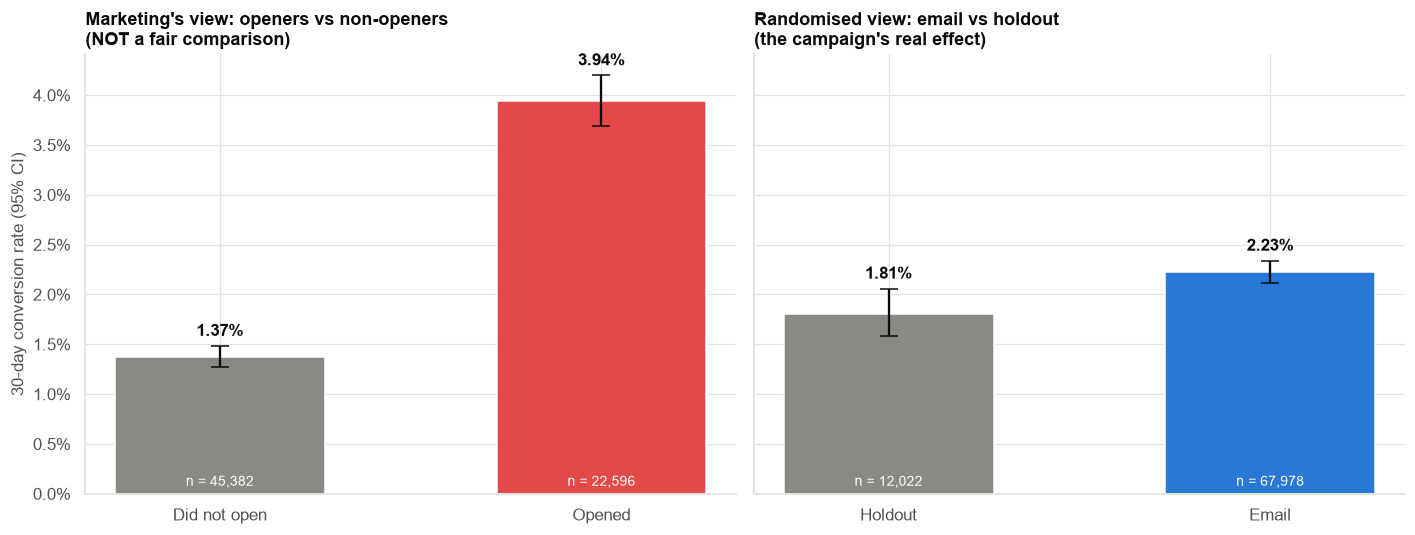

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
panels = [(axes[0], by_open, ["did not open", "opened"], [INK_MUTED, COLORS["red"]],
           "Marketing's view: openers vs non-openers\n(NOT a fair comparison)"),
          (axes[1], by_group, ["holdout", "email"], [INK_MUTED, PRIMARY],
           "Randomised view: email vs holdout\n(the campaign's real effect)")]
for ax, tbl, order, colors, title in panels:
    t = tbl.loc[order]
    ax.bar(range(2), t["rate"], color=colors, width=0.55)
    ax.errorbar(range(2), t["rate"], yerr=[t["rate"] - t["ci_low"], t["ci_high"] - t["rate"]],
                fmt="none", ecolor=INK, capsize=6)
    for i, (_, r) in enumerate(t.iterrows()):
        ax.text(i, r["ci_high"] + 0.001, f"{r['rate']:.2%}", ha="center", fontweight="bold")
        ax.text(i, 0.0008, f"n = {int(r['customers']):,}", ha="center", color="white", fontsize=9)
    ax.set_xticks(range(2), [o.capitalize() for o in order])
    ax.set_title(title, fontsize=12)
    ax.yaxis.set_major_formatter(pct)
axes[0].set_ylabel("30-day conversion rate (95% CI)")
fig.tight_layout()
save_fig(fig, "fig01_wrong_vs_right_comparison", PATHS["figures"])
plt.show()

**Observation.** Openers convert at almost three times the rate of non-openers. The email group as a whole
converts only modestly more than the holdout.

**Interpretation.** Opening is **not randomly assigned**: customers *choose* to open. The customers who open
marketing emails are the engaged, active customers, who are also more likely to want and take a loan anyway.
Openers vs non-openers therefore compares **two different kinds of customer**, a textbook case of **selection
bias** (self-selection). The email vs holdout comparison is protected by randomisation.

**Business implication.** The "3×" figure overstates the email's effect several-fold. Doubling the budget on that
basis would be a mistake.

**Caveat.** The randomised comparison measures the effect of *sending* the email to everyone (including people who
never open it). This "intent-to-treat" effect is what the business controls, and so it is the right basis for a
send/don't-send decision.

### Figure 2 — Proof that openers are different people: engagement predicts conversion even without an email

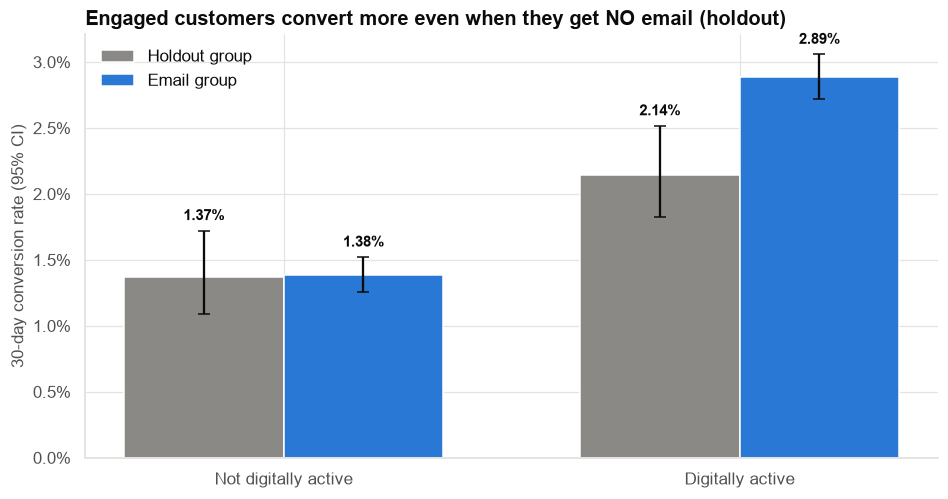

In [9]:
eng = rate_table(camp, ["group", "digital_active"]).reset_index()
eng["digital_active"] = eng["digital_active"].map({0: "Not digitally active", 1: "Digitally active"})
save_table(eng, "conversion_by_engagement", PATHS["tables"], index=False)

fig, ax = plt.subplots(figsize=(10, 5))
width = 0.35
for j, (grp, color) in enumerate([("holdout", INK_MUTED), ("email", PRIMARY)]):
    t = eng[eng["group"] == grp]
    x = np.arange(2) + (j - 0.5) * width
    ax.bar(x, t["rate"], width=width, color=color, label=f"{grp.capitalize()} group")
    ax.errorbar(x, t["rate"], yerr=[t["rate"] - t["ci_low"], t["ci_high"] - t["rate"]], fmt="none", ecolor=INK, capsize=4)
    for xi, r, hi in zip(x, t["rate"], t["ci_high"]):
        ax.text(xi, hi + 0.0008, f"{r:.2%}", ha="center", fontsize=10, fontweight="bold")
ax.set_xticks(range(2), ["Not digitally active", "Digitally active"])
ax.yaxis.set_major_formatter(pct)
ax.set(title="Engaged customers convert more even when they get NO email (holdout)",
       ylabel="30-day conversion rate (95% CI)")
ax.legend(loc="upper left")
save_fig(fig, "fig02_engagement_confounding", PATHS["figures"])
plt.show()

**Observation.** In the holdout, which received no email, digitally active customers convert at about 2.1% vs about
1.4% for inactive ones. Among inactive customers the email adds almost nothing. Among active customers it adds
noticeably more.

**Interpretation.** Engagement raises conversion **on its own**, without any email. Engaged customers are also
the ones who open emails. Engagement is therefore a **confounder** of the opened-vs-not comparison: it drives both
"opening" and "converting". Randomisation of the *send* breaks this link; self-selected *opening* does not.

**Business implication.** The email seems to work mainly through engaged customers. That suggests targeting
(Section 17), but treat it as a hypothesis: we did not plan this subgroup comparison in advance (Case 19).

**Caveat.** `digital_active` is only a partial proxy for engagement. Even within it, openers would still differ
from non-openers in ways we cannot see.

## Section 8 — Statistical method selection

### Q1: Did the email increase conversion?

```text
Outcome          : binary (converted 0/1), so we compare two PROPORTIONS
Groups           : two independent, randomised groups (email n ≈ 68,000; holdout n ≈ 12,000)
Counts           : ≈ 1,500 and ≈ 220 conversions, all expected counts far above 10
Direction        : two-sided (an email could also annoy people and reduce conversion)
Estimand         : the difference in conversion rates (absolute lift), plus the ratio (relative lift)
```

| Method | Verdict |
|---|---|
| **Two-proportion z-test** + **CI for the difference** (Newcombe/Wilson-based) | ✅ **Selected.** Standard, large counts, gives the lift in percentage points with a CI. |
| Chi-square test on the 2×2 table | ✅ Equivalent: for a 2×2 table, χ² = z². Same p-value, but no CI and no direction. |
| **Permutation test** | ✅ Used as an assumption-free check: shuffle the group labels and see how often a lift this large appears. |
| Fisher's exact test | Valid but unnecessary at these counts. Reserved for the pilot. |
| t-test on the 0/1 outcome | Gives nearly the same answer at large n, but the proportion test is the natural, standard choice. |

### Q4: Did the RM call work?

```text
Outcome          : binary; two randomised groups of 180
Counts           : single-digit conversions → some EXPECTED counts below 5
```

The z-test and chi-square rely on a **normal approximation** to the binomial that needs reasonably large expected
counts (rules of thumb: n·p ≥ 10, or all expected cell counts ≥ 5). With single-digit counts the approximation can
be badly off. **Fisher's exact test** computes the probability directly from the hypergeometric distribution, with
no approximation, so it is the selected method.

## Section 9 — Assumption checking

| Assumption | Check | Result |
|---|---|---|
| **Random assignment** | SRM test p ≈ 0.8; groups balanced on segment, tenure, digital activity | ✅ |
| **Independence** between customers | One row per customer; email sends don't interact (no referral/network effects) | ✅ (reasonable) |
| **Each customer counted once, outcome measured the same way in both groups** | Same 30-day window and same loan system for both groups | ✅ |
| **Large-sample normal approximation** (z-test) | Smallest expected count ≈ 220 conversions in holdout | ✅ |
| **SUTVA / no contamination**: holdout customers did not receive the email another way | Checked with CRM: holdout suppressed from all channels for 30 days | ✅ (per Marketing) |
| Pilot: large-sample approximation | Expected conversions per arm ≈ 3.5 | ❌ → use **Fisher's exact** |

## Section 10 — Analysis

### 10.1 Two-proportion z-test, by hand

In [10]:
x_e, n_e = int(by_group.loc["email", "conversions"]), int(by_group.loc["email", "customers"])
x_h, n_h = int(by_group.loc["holdout", "conversions"]), int(by_group.loc["holdout", "customers"])
p_e, p_h = x_e / n_e, x_h / n_h
lift = p_e - p_h

# Test statistic: under H0 (no effect) both groups share one rate -> use the POOLED rate for the SE.
p_pool = (x_e + x_h) / (n_e + n_h)
se_pooled = np.sqrt(p_pool * (1 - p_pool) * (1 / n_e + 1 / n_h))
z = lift / se_pooled
p_value = 2 * stats.norm.sf(abs(z))

# Confidence interval: no H0 assumed -> use each group's own rate (unpooled SE).
se_unpooled = np.sqrt(p_e * (1 - p_e) / n_e + p_h * (1 - p_h) / n_h)
wald_ci = (lift - 1.96 * se_unpooled, lift + 1.96 * se_unpooled)
newcombe = confint_proportions_2indep(x_e, n_e, x_h, n_h, method="newcomb", compare="diff")

print(f"Email:   {x_e:,}/{n_e:,} = {p_e:.3%}")
print(f"Holdout: {x_h:,}/{n_h:,} = {p_h:.3%}")
print(f"Absolute lift = {lift * 100:.3f} percentage points")
print(f"Pooled rate = {p_pool:.4%}, pooled SE = {se_pooled * 100:.4f} pp  ->  z = {z:.2f}, two-sided p = {p_value:.4f}")
print(f"95% CI for lift (Wald, unpooled SE {se_unpooled * 100:.4f} pp): [{wald_ci[0] * 100:.3f}, {wald_ci[1] * 100:.3f}] pp")
print(f"95% CI for lift (Newcombe):                   [{newcombe[0] * 100:.3f}, {newcombe[1] * 100:.3f}] pp")
z_sm, p_sm = proportions_ztest([x_e, x_h], [n_e, n_h])
print(f"statsmodels check: z = {z_sm:.2f}, p = {p_sm:.4f}")
chi2 = stats.chi2_contingency([[x_e, n_e - x_e], [x_h, n_h - x_h]], correction=False)
print(f"Chi-square on the 2x2 table: chi2 = {chi2.statistic:.3f} = z² = {z ** 2:.3f}, p = {chi2.pvalue:.4f}")

Email:   1,513/67,978 = 2.226%
Holdout: 217/12,022 = 1.805%
Absolute lift = 0.421 percentage points
Pooled rate = 2.1625%, pooled SE = 0.1439 pp  ->  z = 2.92, two-sided p = 0.0035
95% CI for lift (Wald, unpooled SE 0.1340 pp): [0.158, 0.683] pp
95% CI for lift (Newcombe):                   [0.145, 0.671] pp
statsmodels check: z = 2.92, p = 0.0035
Chi-square on the 2x2 table: chi2 = 8.545 = z² = 8.545, p = 0.0035


**Why two different standard errors?** For the *test*, we ask "how surprising is this lift *if there were no
effect*?", so we use the SE implied by H₀, where both groups share one pooled rate. For the *confidence interval*,
we make no such assumption and use each group's own rate. At these sample sizes the two SEs are nearly identical.
In small samples the distinction matters.

### 10.2 Relative lift and effect size

In [11]:
rel = confint_proportions_2indep(x_e, n_e, x_h, n_h, method="log", compare="ratio")
rel_lift = p_e / p_h - 1
h = cohens_h(p_e, p_h)
print(f"Relative lift = {rel_lift:+.1%}  (95% CI {rel[0] - 1:+.1%} to {rel[1] - 1:+.1%})")
print(f"Cohen's h = {h:.3f}  ('tiny' on textbook scales: 0.2 small, 0.5 medium)")

Relative lift = +23.3%  (95% CI +7.1% to +42.0%)
Cohen's h = 0.030  ('tiny' on textbook scales: 0.2 small, 0.5 medium)


**Absolute vs relative lift.** "+23%" and "+0.42 percentage points" describe the same result.

- Relative lift sounds impressive and is what marketing decks like to quote. It depends heavily on the base rate:
  +23% of 1.8% is tiny in absolute terms.
- Absolute lift tells you **how many extra customers converted**: 0.42 extra loans per 100 emails, about **one extra
  loan per 240 emails**. This is the number that drives revenue.

**Always report both, and lead with the absolute lift when money is at stake.** Note too that the relative-lift CI is
wide (roughly +7% to +42%). One campaign does not pin it down precisely.

Cohen's h ≈ 0.03 is "tiny" on the usual scale, which shows again that **textbook effect-size labels are not
business thresholds**. A tiny lift on a cheap action sent to millions can be very valuable.

### 10.3 Permutation test: what does "no effect" look like?

Permutation p-value (two-sided, 5,000 shuffles) = 0.0052   (z-test: 0.0035)


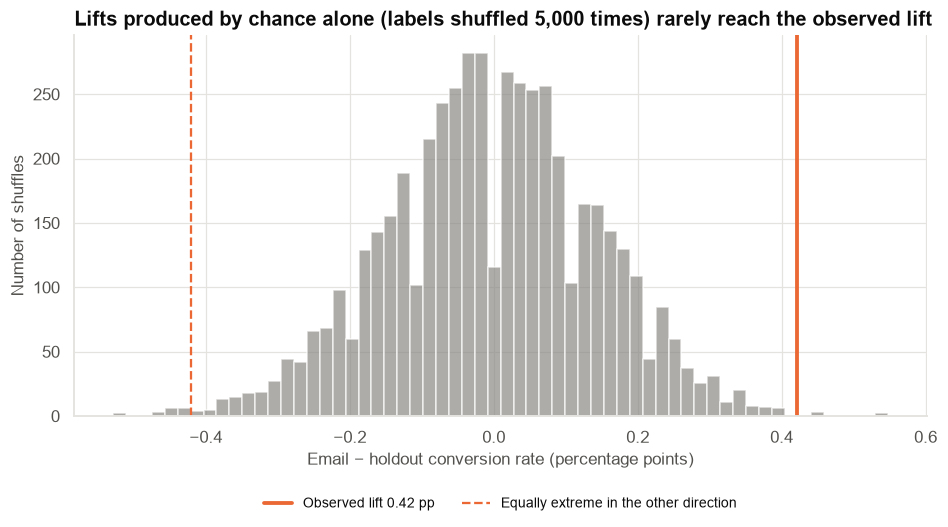

In [12]:
y = camp["converted"].to_numpy()
is_email = (camp["group"] == "email").to_numpy()
n_perm = 5_000
perm_diffs = np.empty(n_perm)
for i in range(n_perm):
    shuffled = rng.permutation(is_email)          # break any link between group and outcome
    perm_diffs[i] = y[shuffled].mean() - y[~shuffled].mean()
p_perm = np.mean(np.abs(perm_diffs) >= abs(lift))
print(f"Permutation p-value (two-sided, {n_perm:,} shuffles) = {p_perm:.4f}   (z-test: {p_value:.4f})")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(perm_diffs * 100, bins=60, color=INK_MUTED, alpha=0.7, edgecolor="white")
ax.axvline(lift * 100, color=HIGHLIGHT, lw=2.5, label=f"Observed lift {lift * 100:.2f} pp")
ax.axvline(-lift * 100, color=HIGHLIGHT, lw=1.5, ls="--", label="Equally extreme in the other direction")
ax.set(title="Lifts produced by chance alone (labels shuffled 5,000 times) rarely reach the observed lift",
       xlabel="Email − holdout conversion rate (percentage points)", ylabel="Number of shuffles")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9)
save_fig(fig, "fig03_permutation_test", PATHS["figures"])
plt.show()

The permutation test makes the p-value concrete. If the email had no effect, the group labels would be
arbitrary. Reshuffling them thousands of times shows the range of "lifts" pure chance produces. Our observed lift
sits far in the tail, and the permutation p-value agrees with the z-test. With large samples the normal
approximation is excellent.

### 10.4 Is the lift worth it? A CI-based decision

In [13]:
campaign_cost = FIXED_COST + COST_PER_EMAIL * n_e
breakeven_lift = campaign_cost / (n_e * VALUE_PER_LOAN)
incr_loans = lift * n_e
incr_loans_ci = (newcombe[0] * n_e, newcombe[1] * n_e)
net_value = incr_loans * VALUE_PER_LOAN - campaign_cost
net_value_ci = (incr_loans_ci[0] * VALUE_PER_LOAN - campaign_cost, incr_loans_ci[1] * VALUE_PER_LOAN - campaign_cost)
econ = pd.Series({
    "emails sent": n_e,
    "campaign cost (₹ lakh)": campaign_cost / 1e5,
    "break-even lift (pp)": breakeven_lift * 100,
    "incremental loans (estimate)": incr_loans,
    "incremental loans (CI low)": incr_loans_ci[0],
    "incremental loans (CI high)": incr_loans_ci[1],
    "net value (₹ lakh, estimate)": net_value / 1e5,
    "net value (₹ lakh, CI low)": net_value_ci[0] / 1e5,
    "net value (₹ lakh, CI high)": net_value_ci[1] / 1e5,
    "ROI multiple (estimate)": (incr_loans * VALUE_PER_LOAN) / campaign_cost,
})
save_table(econ.to_frame("value"), "campaign_economics", PATHS["tables"])
econ.to_frame("value")

,value
emails sent,"67,978.0000"
campaign cost (₹ lakh),2.1699
break-even lift (pp),0.0355
incremental loans (estimate),285.9807
incremental loans (CI low),98.3982
incremental loans (CI high),456.1439
"net value (₹ lakh, estimate)",23.5683
"net value (₹ lakh, CI low)",6.6859
"net value (₹ lakh, CI high)",38.8830
ROI multiple (estimate),11.8613


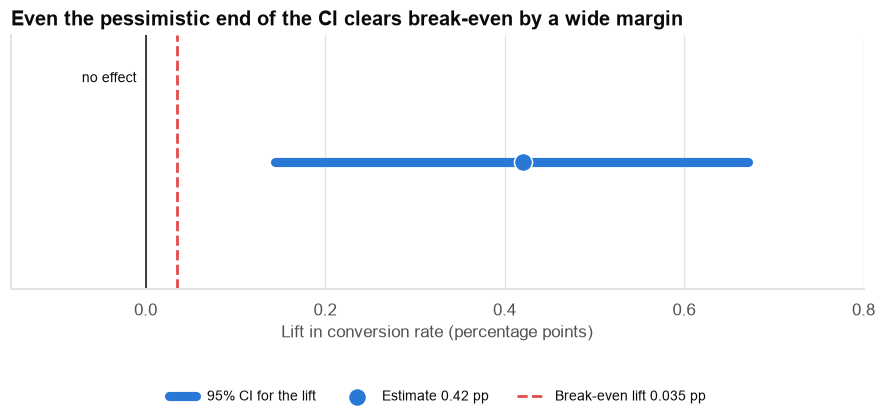

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.0))
ax.plot([newcombe[0] * 100, newcombe[1] * 100], [0, 0], color=PRIMARY, lw=6, solid_capstyle="round",
        label="95% CI for the lift")
ax.scatter(lift * 100, 0, s=140, color=PRIMARY, edgecolor="white", zorder=3, label=f"Estimate {lift * 100:.2f} pp")
ax.axvline(0, color=INK, lw=1)
ax.axvline(breakeven_lift * 100, color=COLORS["red"], ls="--", lw=1.8, label=f"Break-even lift {breakeven_lift * 100:.3f} pp")
ax.text(-0.01, 0.25, "no effect", ha="right", fontsize=9, color=INK)
ax.set_ylim(-0.4, 0.4)
ax.set_yticks([])
ax.set_xlim(-0.15, 0.8)
ax.set(title="Even the pessimistic end of the CI clears break-even by a wide margin",
       xlabel="Lift in conversion rate (percentage points)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3, fontsize=9)
save_fig(fig, "fig04_lift_vs_breakeven", PATHS["figures"])
plt.show()

This is the most useful way to read a CI for a decision. Compare the **whole interval** with the thresholds that
matter:

- **Zero** (no effect): the CI excludes it, so the email has a positive effect (consistent with p ≈ 0.003).
- **Break-even** (≈ 0.035 pp): the campaign costs very little per email. Even the lower end of the CI is about four
  times break-even, so the campaign pays under any plausible value of the true lift.

When the CI straddles the decision threshold, the honest answer is "we don't know yet" (Case 22).

### 10.5 How much does the email do for people who actually open it? (Advanced)

Marketing's 3× number tries to answer a reasonable question, *what does the email do for those who read it?*, with
a biased comparison. Because the holdout could not open an email, there is a simple unbiased estimator: the
**complier average causal effect** (CACE), equal to the intent-to-treat lift ÷ the open rate. It assumes the
email has no effect on people who don't open it.

In [15]:
open_rate = email["email_opened"].mean()
cace = lift / open_rate
naive = by_open.loc["opened", "rate"] - by_open.loc["did not open", "rate"]
print(f"Intent-to-treat lift (all emailed)      : {lift * 100:.2f} pp")
print(f"Open rate                               : {open_rate:.1%}")
print(f"Effect among openers (CACE = ITT / open): {cace * 100:.2f} pp")
print(f"Naive openers − non-openers difference  : {naive * 100:.2f} pp  <- about {naive / cace:.1f}× too large")

Intent-to-treat lift (all emailed)      : 0.42 pp
Open rate                               : 33.2%
Effect among openers (CACE = ITT / open): 1.27 pp
Naive openers − non-openers difference  : 2.57 pp  <- about 2.0× too large


The email raises conversion among openers by roughly 1.3 percentage points, about half of the naive 2.6 pp gap.
The rest of the naive gap comes from openers being different customers. (This is an instrumental-variable
argument. Case 21 discusses causal designs more broadly.)

### 10.6 The RM-call pilot: small counts and Fisher's exact test

In [16]:
pilot_tbl = pd.crosstab(pilot["arm"], pilot["converted"]).loc[["rm_call", "no_call"], [1, 0]]
pilot_tbl.columns = ["converted", "not converted"]
display(pilot_tbl)
exp = stats.contingency.expected_freq(pilot_tbl.to_numpy())
print("Expected counts under independence:\n", np.round(exp, 1))

fisher = stats.fisher_exact(pilot_tbl.to_numpy(), alternative="two-sided")
chi_p = stats.chi2_contingency(pilot_tbl.to_numpy(), correction=False).pvalue
z_p = proportions_ztest(pilot_tbl["converted"].to_numpy(), pilot_tbl.sum(axis=1).to_numpy())[1]
k1, k0 = pilot_tbl.loc["rm_call", "converted"], pilot_tbl.loc["no_call", "converted"]
pilot_ci = confint_proportions_2indep(k1, 180, k0, 180, method="newcomb", compare="diff")
print(f"\nConversion: RM call {k1}/180 = {k1 / 180:.1%},  no call {k0}/180 = {k0 / 180:.1%}")
print(f"Difference = {(k1 - k0) / 180 * 100:.1f} pp, 95% Newcombe CI [{pilot_ci[0] * 100:.1f}, {pilot_ci[1] * 100:.1f}] pp")
print(f"z-test / chi-square (INVALID here) p = {z_p:.3f} / {chi_p:.3f}")
print(f"Fisher's exact test (valid)        p = {fisher.pvalue:.3f}")

pilot_res = pd.Series({"conv_rm_call": k1 / 180, "conv_no_call": k0 / 180, "diff_pp": (k1 - k0) / 180 * 100,
                       "diff_ci_low_pp": pilot_ci[0] * 100, "diff_ci_high_pp": pilot_ci[1] * 100,
                       "fisher_p": fisher.pvalue, "z_test_p": z_p, "min_expected_count": exp.min()})
save_table(pilot_res.to_frame("value"), "pilot_results", PATHS["tables"])

,converted,not converted
arm,,
rm_call,6,174
no_call,1,179


Expected counts under independence:
 [[  3.5 176.5]
 [  3.5 176.5]]

Conversion: RM call 6/180 = 3.3%,  no call 1/180 = 0.6%
Difference = 2.8 pp, 95% Newcombe CI [-0.3, 6.6] pp
z-test / chi-square (INVALID here) p = 0.056 / 0.056
Fisher's exact test (valid)        p = 0.121


WindowsPath('C:/Users/11624/OneDrive - Indian School of Business/Documents/personal/stats_case_study/case_studies/03_email_campaign_conversion/outputs/tables/pilot_results.csv')

**What happened here is important.** The approximate tests give p ≈ 0.06, tantalisingly close to 0.05. The exact
test gives **p ≈ 0.12**. Some expected counts are below 5 (about 3.5), so the normal approximation is unreliable, and
here it makes the evidence look stronger than it is. With small counts, **always use the exact test**.

**Reading the pilot honestly.**
- The point estimate is large: 3.3% vs 0.6%, i.e. one extra conversion per 36 calls.
- But the evidence is weak: 6 vs 1 conversions. The CI for the difference runs from about **−0.3 to +6.6
  percentage points**. It includes zero, and it also includes very large effects.
- **"Not statistically significant" does not mean "doesn't work".** It means this pilot was **too small to tell**.
  The right decision is neither "scale it" nor "kill it" but "**run a properly sized pilot**" (Cases 04 and 22
  show how to size it).

In [17]:
# How big would a conclusive pilot need to be? (80% power, alpha 5%, two-sided)
from statsmodels.stats.power import NormalIndPower
scenarios = {"pilot's point estimate (3.3% vs 0.6%)": (k1 / 180, k0 / 180),
             "more conservative (2.5% vs 1.0%)": (0.025, 0.010)}
for name, (pa, pb) in scenarios.items():
    n_arm = NormalIndPower().solve_power(effect_size=cohens_h(pa, pb), alpha=0.05, power=0.8, ratio=1.0)
    print(f"{name:40s}: about {np.ceil(n_arm):,.0f} customers per arm")

pilot's point estimate (3.3% vs 0.6%)   : about 331 customers per arm


more conservative (2.5% vs 1.0%)        : about 1,143 customers per arm


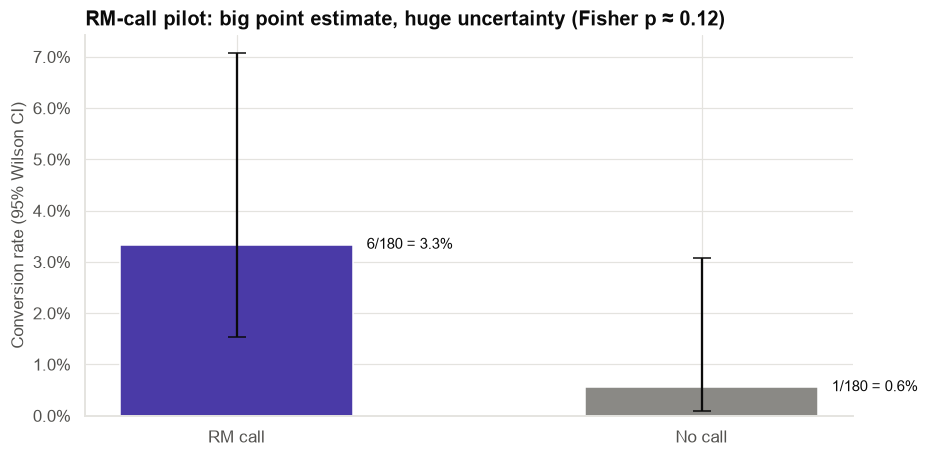

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
rates = [k1 / 180, k0 / 180]
cis = [proportion_ci(k1, 180), proportion_ci(k0, 180)]
ax.bar([0, 1], rates, color=[COLORS["violet"], INK_MUTED], width=0.5)
ax.errorbar([0, 1], rates, yerr=[[r - c["lower"] for r, c in zip(rates, cis)], [c["upper"] - r for r, c in zip(rates, cis)]],
            fmt="none", ecolor=INK, capsize=6)
for i, (r, k) in enumerate(zip(rates, [k1, k0])):
    ax.text(i + 0.28, r, f"{k}/180 = {r:.1%}", va="center", fontsize=10)
ax.set_xticks([0, 1], ["RM call", "No call"])
ax.yaxis.set_major_formatter(pct)
ax.set(title="RM-call pilot: big point estimate, huge uncertainty (Fisher p ≈ 0.12)", ylabel="Conversion rate (95% Wilson CI)")
save_fig(fig, "fig05_rm_pilot", PATHS["figures"])
plt.show()

## Section 11 — Results

In [19]:
results = pd.DataFrame([
    ["Email campaign: absolute lift (pp)", lift * 100, newcombe[0] * 100, newcombe[1] * 100, f"two-proportion z = {z:.2f}", p_value],
    ["Email campaign: relative lift", rel_lift, rel[0] - 1, rel[1] - 1, "log-ratio CI", np.nan],
    ["Email campaign: incremental loans", incr_loans, incr_loans_ci[0], incr_loans_ci[1], "lift × emails", np.nan],
    ["Email campaign: net value (₹ lakh)", net_value / 1e5, net_value_ci[0] / 1e5, net_value_ci[1] / 1e5, "economics", np.nan],
    ["Effect among openers, CACE (pp)", cace * 100, np.nan, np.nan, "ITT / open rate", np.nan],
    ["Naive openers vs non-openers gap (pp)", naive * 100, np.nan, np.nan, "biased comparison", np.nan],
    ["RM pilot: difference (pp)", (k1 - k0) / 180 * 100, pilot_ci[0] * 100, pilot_ci[1] * 100, "Fisher's exact", fisher.pvalue],
], columns=["quantity", "estimate", "ci_low", "ci_high", "method", "p_value"]).set_index("quantity")
save_table(results, "key_results", PATHS["tables"])
results.assign(p_value=results["p_value"].map(fmt_p))

,estimate,ci_low,ci_high,method,p_value
quantity,,,,,
Email campaign: absolute lift (pp),0.4207,0.1448,0.6710,two-proportion z = 2.92,0.003
Email campaign: relative lift,0.2331,0.0710,0.4197,log-ratio CI,n/a
Email campaign: incremental loans,285.9807,98.3982,456.1439,lift × emails,n/a
Email campaign: net value (₹ lakh),23.5683,6.6859,38.8830,economics,n/a
"Effect among openers, CACE (pp)",1.2656,NaN,NaN,ITT / open rate,n/a
Naive openers vs non-openers gap (pp),2.5660,NaN,NaN,biased comparison,n/a
RM pilot: difference (pp),2.7778,-0.3203,6.5527,Fisher's exact,0.121


## Section 12 — Interpretation

**The email campaign worked, modestly.** Customers randomly chosen to receive the email converted at **2.23%**,
vs **1.81%** in the randomly held-out group: an absolute lift of **+0.42 percentage points** (95% CI ≈ +0.14 to
+0.67 pp), or **+23%** in relative terms (95% CI ≈ +7% to +42%). The two-proportion z-test gives z ≈ 2.9, p ≈ 0.003.
If the email had no effect, a lift this large would arise by chance in fewer than 1 in 250 campaigns of this
size. A permutation test, which needs no normal approximation, agrees.

**Because the holdout was randomised, this is a causal estimate.** Sending the email *caused* roughly 290 extra
personal loans (95% CI ≈ 100 to 460) among the 68,000 customers emailed. The randomisation checks (SRM, balance)
give no reason to doubt the design.

**The "3× for openers" claim is not a valid measure of the effect.** Openers are self-selected, more engaged
customers who convert more even without an email (shown in the holdout). Using the holdout, the effect of the
email *among openers* is about +1.3 pp, roughly half of the naive 2.6 pp gap.

**The campaign pays comfortably.** At ₹9,000 net value per incremental loan and a total cost of about ₹2.2 lakh,
break-even needs a lift of only ≈ 0.035 pp. The whole CI lies far above that, so the campaign's value is
positive under any plausible true lift (roughly ₹7 lakh to ₹39 lakh net).

**The RM-call pilot is inconclusive.** 6 of 180 called customers converted vs 1 of 180 not called. The point
estimate is large, but Fisher's exact test gives p ≈ 0.12, and the CI for the difference (≈ −0.3 to +6.6 pp)
includes both zero and very large effects. The approximate z-test (p ≈ 0.06) is not valid at these counts and
overstates the evidence.

## Section 13 — What can we say?

### ✅ We can confidently say
- The randomisation worked (planned split achieved; groups balanced).
- **Sending the email caused a modest increase in conversion**: about +0.4 pp (+23%), clearly above zero.
- The campaign was **profitable** under Finance's value and cost assumptions, even at the pessimistic end of the CI.
- The "openers converted 3×" comparison is **biased** and should not be used to measure campaign effect.

### 📊 We have evidence that
- The email's effect is concentrated among digitally engaged customers (observed, but not a pre-planned
  comparison, so treat it as a hypothesis).
- Among customers who open, the email raises conversion by roughly 1.3 pp (CACE, under its assumptions).

### ❌ We cannot conclude
- That the RM call works, or that it doesn't. The pilot is too small.
- That the lift will be the same next quarter. Repeated emails may fatigue customers, and offers change.
- That every converted email customer was *incremental*. Only about 1 in 5 email-group conversions (0.42 / 2.23)
  is attributable to the email. The rest would have happened anyway.
- That the 30-day lift is not partly **pull-forward** (loans that would have happened in month 2 anyway).

### 🔍 We would need additional analysis or data to conclude
- A **properly powered RM-call pilot** (Case 04 / 22 sample-size methods).
- A **longer outcome window** (60–90 days) to check pull-forward.
- **Repeated campaigns with holdouts** to measure fatigue.
- A **pre-registered targeting test** (engaged vs non-engaged) before targeting on engagement.

## Section 14 — Business interpretation

| Statistical finding | Data scientist interpretation | Business interpretation | Business action |
|---|---|---|---|
| Lift +0.42 pp (CI 0.14–0.67), p ≈ 0.003; randomised | Causal, positive, modest effect | About 1 extra loan per 240 emails; ~290 extra loans | Approve repeating the campaign |
| Break-even lift ≈ 0.035 pp ≪ CI lower bound | Value positive across the CI | Cheap channel, so even a small lift pays | Keep emailing; don't double spend on the basis of "3×" |
| Openers 3.9% vs non-openers 1.4% | Self-selection bias; engagement confounds | The "3×" headline overstates the email's effect | Retire open-based "lift" from the campaign dashboard; always report vs holdout |
| CACE ≈ 1.3 pp among openers | Effect among readers about half of naive gap | Getting more people to open is worth testing | Test subject lines / timing with holdouts |
| RM pilot 6/180 vs 1/180, Fisher p ≈ 0.12, CI −0.3 to +6.6 pp | Inconclusive; underpowered | Promising but unproven; RM time is expensive | Run a properly sized pilot before scaling |

## Section 15 — Limitations

- **30-day window**: some lift may be pull-forward rather than truly new business.
- **Single campaign**: novelty effects; future campaigns may perform differently (fatigue, seasonality,
  competitor offers).
- **Economics** (₹9,000 per loan, costs) are Finance/Marketing assumptions. The decision is robust to them because
  the lift is far above break-even.
- **Subgroup observations** (engagement) were not pre-registered. They are exploratory.
- **CACE** relies on the assumption that the email does nothing for non-openers (e.g., preview panes and
  subject lines can still influence non-openers).
- **Sampling variation between campaigns**: the realised lift of a single campaign of this size could plausibly
  range from about +0.15 to +0.7 pp. Don't over-interpret one number.
- **Synthetic data.**

## Section 16 — Final recommendation

1. **Sign off the campaign as effective and profitable**, but at **+0.4 pp (+23%)**, not "3×". Repeat it, and
   **keep a random holdout in every send** so the effect can be measured each time.
2. **Do not double the budget on the basis of the openers comparison.** If Marketing wants to scale, test
   *frequency* or *targeting* with randomised holdouts first.
3. **Change the dashboard**: replace "openers vs non-openers" with "email vs holdout, with a confidence interval".
4. **RM calls: do not scale yet.** Run a properly sized pilot: a few hundred customers per arm if the pilot's large
   effect is real, but over a thousand per arm for a more conservative effect (Section 10.6; Case 04 explains the
   calculation).

## Section 17 — What would I do next?

- Size the RM pilot properly (power analysis, Case 04).
- Re-measure conversion at 60 and 90 days to quantify pull-forward.
- Run a **targeting experiment**: randomise within engaged and non-engaged customers to test whether the email
  should only go to engaged customers.
- Track lift across successive campaigns, each with its own holdout, to detect fatigue.

---

### Concepts covered
Bernoulli and binomial distributions · randomised control (holdout) · sample-ratio mismatch · covariate balance ·
two-proportion z-test (pooled vs unpooled SE) · Newcombe CI for a difference in proportions · χ² = z² for 2×2
tables · permutation test · absolute vs relative lift · Cohen's h · CI-based decision vs break-even · selection bias
from self-selected exposure · confounding by engagement · intent-to-treat · complier average causal effect
(preview) · Fisher's exact test and small expected counts · "not significant ≠ no effect".

### Exercises
1. Compute the lift separately for Mass and Affluent customers. Is the difference between segments itself
   statistically significant? (Hint: you need a test of the *difference in lifts*.)
2. Re-run the pilot analysis using a one-sided Fisher test (H₁: the call increases conversion). Would a one-sided
   test have been justified *before* the pilot? Why does that matter?
3. How small could the holdout have been while keeping 80% power for a 0.4 pp lift? What is the cost of a larger
   holdout?